# 04 — How robust are the limits?

**Feeds:** paper §6 (Monte Carlo convergence, Fig. 5) and §8 (systematics). One section per possible source of
error, from the smallest to the largest.

In [1]:
# ---------------------------------------------------------------- settings
SNAPSHOT = "latest"      # "latest" | time stamp or prefix | "newest" | path/to/snapshot.zip | "live"
SAVE_FIGURES = False     # write PDF+PNG of each figure to figures/04/
INCLUDE_METZGER = False   # True adds the one-zone Metzger light curves to the AT2017gfo check
# ---------------------------------------------------------------------------
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "knrates").is_dir())
sys.path.insert(0, str(ROOT))
for _m in [m for m in list(sys.modules) if m.split(".")[0] == "knrates"]:
    del sys.modules[_m]   # always import the repository copy (a kernel may predate a git pull)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from knrates import notebook as NB, figures as F, analysis as A, plotting as P, literature as L
from knrates.stats import summarize_runs

ctx = NB.setup(SNAPSHOT, save_figures=SAVE_FIGURES, fig_dir="figures/04")
runs, lim, M = ctx.runs, ctx.lim, ctx.models
FIX, ISO = "Bu2026Fixed", "Bu2026Vary"

knrates_results_latest.zip (created 20261111T024800Z, git d7af6653)
models: Bu2026Fixed, Bu2026Vary


## 1. Monte Carlo noise (Fig. 5)

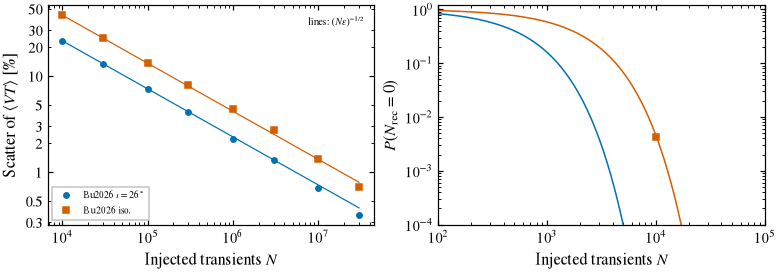

> **Result.** Per 10⁶ injections the ⟨VT⟩ scatter is 2.2–4.6%, as expected from $1/\sqrt{N_{\rm rec}}$; pooled over 10⁸ it is below 0.5%. Monte Carlo noise is negligible.

In [2]:
SIZES = [10_000, 30_000, 100_000, 300_000, 1_000_000, 3_000_000, 10_000_000, 30_000_000]
conv = pd.concat([A.subsampling_convergence(runs, m, SIZES, 3000) for m in M], ignore_index=True)
fig = F.convergence(conv, lim, M); ctx.save(fig, "convergence"); plt.show()
c1 = conv[conv.n_injected == 1_000_000].set_index("model")
NB.finding(f"Per 10⁶ injections the ⟨VT⟩ scatter is {100 * c1.rel_scatter_vt.min():.1f}–{100 * c1.rel_scatter_vt.max():.1f}%, "
           f"as expected from $1/\\sqrt{{N_{{\\rm rec}}}}$; pooled over 10⁸ it is below 0.5%. Monte Carlo noise is negligible.")

## 2. Injection boundary $z_{\max}$

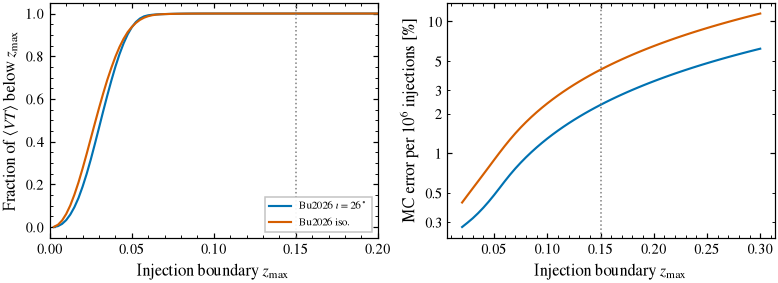

> **Result.** 99.9% of ⟨VT⟩ comes from $z < 0.077$, so $z_{\max} = 0.15$ loses nothing. A boundary near 0.10 would cut the MC error per run roughly in half (right panel); only relevant for new runs.

In [3]:
fig = F.zmax_check(ctx.zh, runs, M); ctx.save(fig, "zmax_check"); plt.show()
cv = A.cumulative_vt_vs_redshift(ctx.zh, runs, FIX)
z99 = float(np.interp(0.999, cv.vt_fraction_below, cv.z_hi))
NB.finding(f"99.9% of ⟨VT⟩ comes from $z < {z99:.3f}$, so $z_{{\\max}} = {runs.z_max.iloc[0]}$ loses nothing. A boundary near "
           f"{1.3 * z99:.2f} would cut the MC error per run roughly in half (right panel); only relevant for new runs.")

## 3. Ejecta parameters: a second parameter set (Suite 07)

In [4]:
l7 = NB.all_limits(SNAPSHOT)
pairs = [("GW170817_Bu2026_FixedView", FIX), ("GW170817_Bu2026_Isotropic", ISO)]
t = pd.DataFrame([dict(model=b, vt_suite01=l7.loc[b, "vt_gpc3_yr"], vt_suite07=l7.loc[a, "vt_gpc3_yr"],
                       r95_suite01=l7.loc[b, "r95"], r95_suite07=l7.loc[a, "r95"]) for a, b in pairs if a in l7.index])
t["vt_change"] = t.vt_suite07 / t.vt_suite01 - 1; display(t.round(4))
NB.finding(f"Lowering the dynamical ejecta mass by 0.1 dex (Suite 07) changes ⟨VT⟩ by {100 * t.vt_change.iloc[0]:+.1f}% "
           f"(fixed angle) and {100 * t.vt_change.iloc[1]:+.1f}% (isotropic): far less than the viewing angle (notebook 03).")

,model,vt_suite01,vt_suite07,r95_suite01,r95_suite07,vt_change
0,Bu2026Fixed,0.0156,0.0157,192,190.6,0.0076
1,Bu2026Vary,0.0045,0.0048,663.6,623.6,0.064


> **Result.** Lowering the dynamical ejecta mass by 0.1 dex (Suite 07) changes ⟨VT⟩ by +0.8% (fixed angle) and +6.4% (isotropic): far less than the viewing angle (notebook 03).

## 4. Do the model light curves look like AT2017gfo?

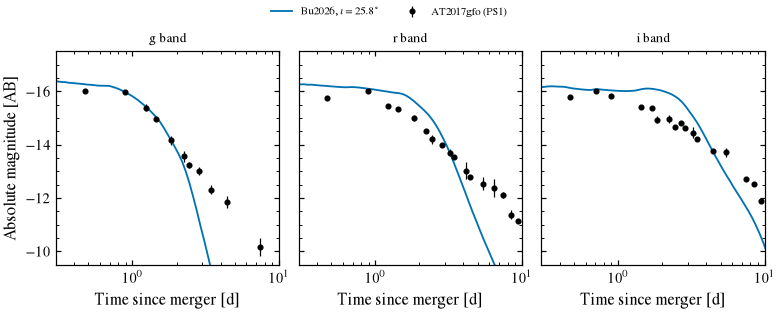

phase                            0-2 d  2-4 d  4-7.5 d
model                      band                       
Bu2026, $\iota=25.8^\circ$ g     -0.07   1.47     6.23
                           i     -0.52  -0.83     0.64
                           r     -0.46   -0.3     2.06

> **Result.** Model minus data (negative = model brighter), first 2 d: g -0.07, r -0.46, i -0.52 mag; after 2 d the model fades faster than AT2017gfo in g (+1.5 mag at 2–4 d). The one-zone Metzger models fail this check and are excluded (docs/decisions.md).

In [5]:
lc = ctx.snap.get("models_lightcurves")
fig, res = F.at2017gfo_lightcurves(lc, include_metzger=INCLUDE_METZGER); ctx.save(fig, "at2017gfo_lightcurves"); plt.show()
display(res.round(2))
r0 = res.xs(res.index.get_level_values(0)[0], level=0)
NB.finding(f"Model minus data (negative = model brighter), first 2 d: g {r0.loc['g', '0-2 d']:+.2f}, r {r0.loc['r', '0-2 d']:+.2f}, "
           f"i {r0.loc['i', '0-2 d']:+.2f} mag; after 2 d the model fades faster than AT2017gfo in g "
           f"({r0.loc['g', '2-4 d']:+.1f} mag at 2–4 d). The one-zone Metzger models fail this check and are excluded "
           "(docs/decisions.md).")

## 5. Selection criteria (summary; details in notebook 05)

In [6]:
fid02 = ctx.snap["suite02_fiducial"].set_index("model")
resp = A.criteria_response(ctx.snap["suite02_slices_1d"], fid02)
display(resp.pivot(index="criterion", columns="model", values="vt_max_over_min").sort_values(FIX, ascending=False).round(2))
r = resp[resp.model == FIX].set_index("criterion")
NB.finding(f"Varying one criterion at a time over its tested range moves ⟨VT⟩ by up to {r.vt_max_over_min.max():.1f}× "
           f"({r.vt_max_over_min.idxmax()}), comparable to the {lim.loc[FIX, 'vt_gpc3_yr'] / lim.loc[ISO, 'vt_gpc3_yr']:.1f}× between "
           "fixed and isotropic viewing and far more than the parameter set or MC noise.")

model,Bu2026Fixed,Bu2026Vary
criterion,,
min_fade_rate,4.03,3.63
snr_threshold_secondary,1.81,1.87
max_timespan_days,1.42,1.36
min_detections,1.38,1.4
snr_threshold,1.24,1.21
min_detections_primary,1.11,1.11
min_time_separation_hours,1.07,1.09
min_rise_rate,1.06,1.05


> **Result.** Varying one criterion at a time over its tested range moves ⟨VT⟩ by up to 4.0× (min_fade_rate), comparable to the 3.5× between fixed and isotropic viewing and far more than the parameter set or MC noise.

## 6. A population instead of one parameter set (Suite 03)

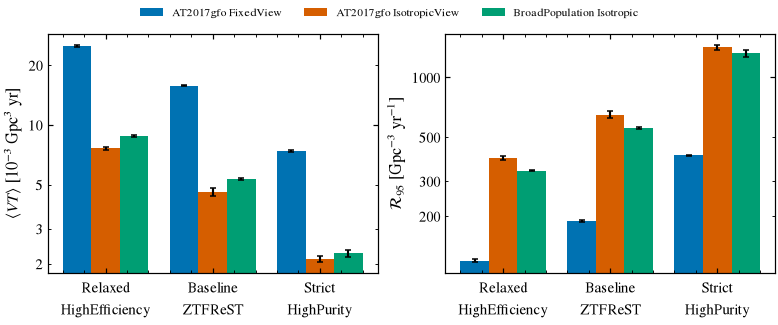

population_type,AT2017gfo_FixedView,AT2017gfo_IsotropicView,BroadPopulation_Isotropic
criteria_regime,,,
Relaxed_HighEfficiency,3.29,1,1.16
Baseline_ZTFReST,3.43,1,1.16
Strict_HighPurity,3.49,1,1.07


> **Result.** With the baseline criteria the broad population has 1.16× the ⟨VT⟩ of AT2017gfo-like ejecta at isotropic viewing (3 realisations of 1,000,000 injections per cell, so a preliminary comparison).

In [7]:
s3 = ctx.snap["suite03_runs"]
REG = [x for x in ["Relaxed_HighEfficiency", "Baseline_ZTFReST", "Strict_HighPurity"] if x in set(s3.criteria_regime)]
POPS = [p for p in sorted(set(s3.population_type)) if not p.startswith("BroadPrior")]
l3 = summarize_runs(s3.rename(columns={"population_type": "model"}), by=("criteria_regime", "model")).rename(columns={"model": "population_type"})
fig = F.population_regimes(l3, REG, POPS); ctx.save(fig, "population_regimes"); plt.show()
p = l3.pivot(index="criteria_regime", columns="population_type", values="vt_gpc3_yr").loc[REG]
display((p.div(p["AT2017gfo_IsotropicView"], axis=0)).round(2))
NB.finding(f"With the baseline criteria the broad population has {p.loc['Baseline_ZTFReST', 'BroadPopulation_Isotropic'] / p.loc['Baseline_ZTFReST', 'AT2017gfo_IsotropicView']:.2f}× "
           f"the ⟨VT⟩ of AT2017gfo-like ejecta at isotropic viewing ({s3.groupby(['criteria_regime', 'population_type']).size().min()} "
           f"realisations of {s3.n_simulated.iloc[0]:,.0f} injections per cell, so a preliminary comparison).")